In [62]:
# Experiment to test the performance of different IP forward models from MPA and Cole  

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import torch

from anemone.experiment import *
from anemone.forwards import *
from anemone.inversion import SmoothModelColeCole, FewLayerColeCole

In [63]:
tx = Loop.square(3)
rx = Receiver(x=13)
waveform = Waveform.example()
recfilter = FilterChain([ButterworthFilter(2.4e5,1),
                         ButterworthFilter(6.2e5,1),
                         ButterworthFilter(4.5e5,1)])

In [64]:
# Define the MPA model characteristics, Transmitter and Receiver size and position
# and the waveform to be used. 
times = torch.logspace(-5, -3, 32)
fwrTD = Forward.mpa(tx, rx, times, filterfunc=recfilter)


frqs = torch.logspace(3,6,51)
fwrFD = ForwardFD.mpa(tx, rx, frqs, filterfunc=recfilter)

c:\users\au653994\onedrive - aarhus universitet\documents\phd\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [65]:
# Define the model parameters fopr the MPA model. It needs the following parameters:
# rho: resistivity of the layers in Ohm*m
# thickness: thickness of the layers in m
# tau: relaxation time of the layers in s
# c: Cole-Cole parameter of the layers (0 < c < 1)
# phi: porosity of the layers (0 < phi < 1)
# The model is defined as a list of layers, where the first layer is the top layer and the last layer is the bottom layer.


#rho = torch.tensor([1,1], dtype=torch.double)
phi_max = torch.tensor([0.2,0.2], dtype=torch.double)
tau_phi = torch.tensor([1e-4, 1e-4], dtype=torch.double)
c = torch.ones(2, dtype=torch.double) * 0.6

thickness = torch.tensor([50], dtype=torch.double)

# Rho values
rho_values = torch.logspace(start=torch.log10(torch.tensor(10.0)), 
                            end=torch.log10(torch.tensor(2000.0)), 
                            steps=100, dtype=torch.double)
# Colormap
cmap = cm.get_cmap('viridis')
norm = mcolors.Normalize(vmin=rho_values.min().item(), vmax=rho_values.max().item())
sm = cm.ScalarMappable(cmap=cmap, norm=norm)


C:\Users\au653994\AppData\Local\Temp\ipykernel_1732\429182235.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis')


c:\Users\au653994\AppData\Local\anaconda3\envs\anemone\lib\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\au653994\AppData\Local\anaconda3\envs\anemone\lib\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


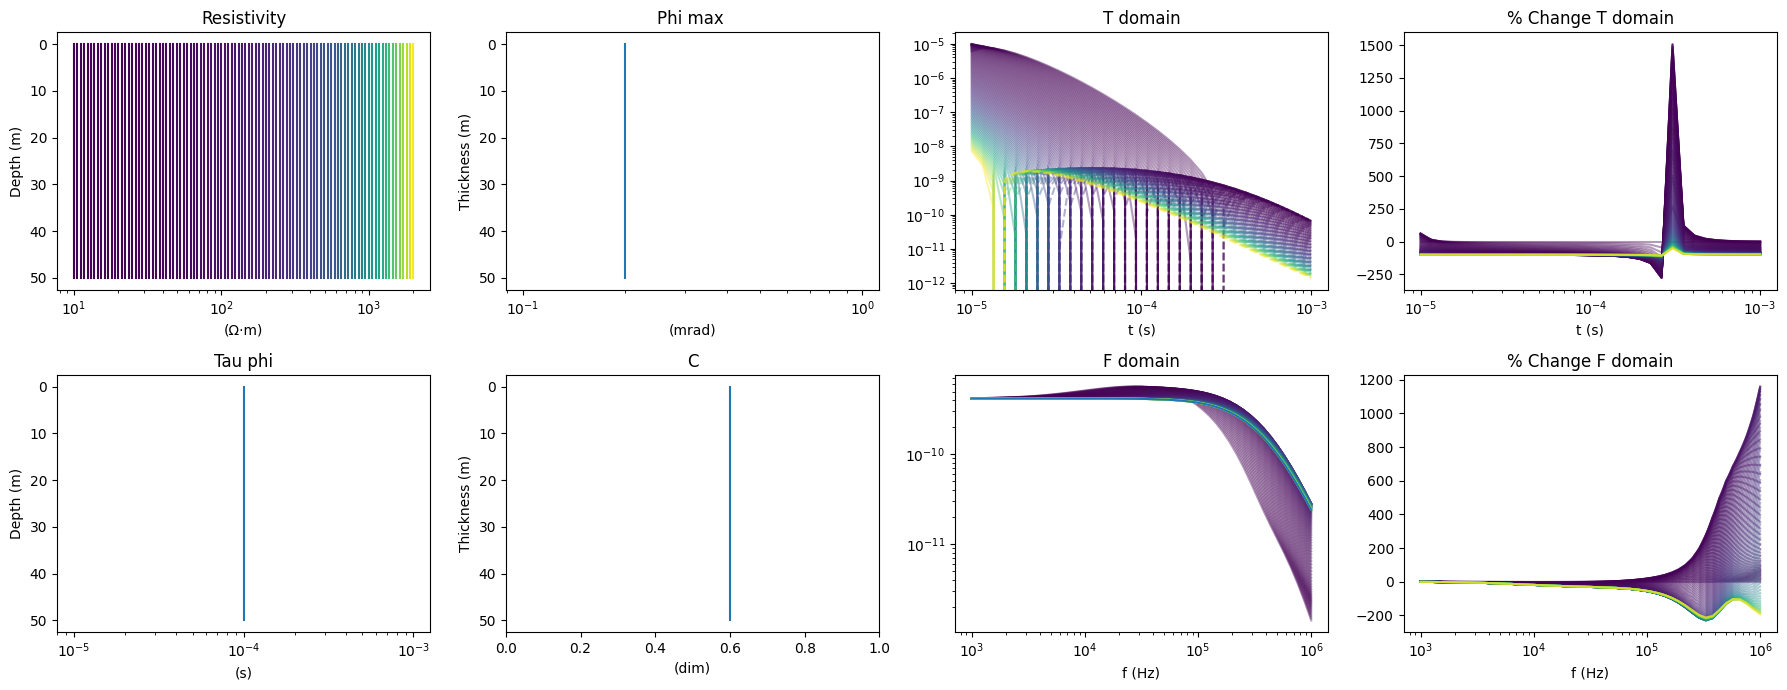

In [66]:
fig,axs = plt.subplots(2, 4, figsize=(18, 7))

# Reference model
rho_ref = torch.tensor([rho_values[0].item(), rho_values[0].item()], dtype=torch.double)
dbdt_ref = fwrTD(rho_ref, phi_max, tau_phi, c, thickness)
dbdf_ref = fwrFD(rho_ref, phi_max, tau_phi, c, thickness)

for rho_val in rho_values:
    color = cmap(norm(rho_val.item()))
    axs[0,0].semilogx([rho_val.item(), rho_val.item()], [0, thickness[0].item()], color=color, linestyle='-')


# Add labels and title for clarity
axs[0, 0].set_xlabel('(Ω·m)')
axs[0, 0].set_ylabel('Depth (m)')
axs[0, 0].set_title('Resistivity')
axs[0, 0].invert_yaxis()  # Optional: makes depth increase downward

axs[0,1].semilogx([phi_max[0].item(), phi_max[0].item()], [0, thickness[0].item()], color='C0', linestyle='-')
axs[0,1].set_xlabel('(mrad)')
axs[0,1].set_ylabel('Thickness (m)')
axs[0,1].set_title('Phi max ')
axs[0,1].invert_yaxis()  # Optional: makes depth increase downward

axs[1,0].semilogx([tau_phi[0].item(), tau_phi[0].item()], [0, thickness[0].item()], color='C0', linestyle='-')
axs[1,0].set_xlabel('(s)')
axs[1,0].set_ylabel('Depth (m)')
axs[1,0].set_title('Tau phi')
axs[1,0].invert_yaxis()  # Optional: makes depth increase downward

axs[1,1].plot([c[0].item(), c[0].item()], [0, thickness[0].item()], color='C0', linestyle='-')
axs[1,1].set_xlim(0, 1)
axs[1,1].set_xlabel('(dim)')
axs[1,1].set_ylabel('Thickness (m)')
axs[1,1].set_title('C')
axs[1,1].invert_yaxis()  # Optional: makes depth increase downward

# Compute the model response for the MPA model
for rho_val in rho_values:
    rho = torch.tensor([rho_val.item(), rho_val.item()], dtype=torch.double)

    dbdt = fwrTD(rho, phi_max,tau_phi,c, thickness)
    dbdf = fwrFD(rho, phi_max,tau_phi,c, thickness)

    color = cmap(norm(rho_val.item()))
    axs[0,2].loglog(times, dbdt, color=color, linestyle='-', alpha=0.4)
    axs[0,2].loglog(times, -dbdt, color=color, linestyle='--', alpha=0.4)
    axs[1,2].loglog(frqs, torch.abs(dbdf), color=color, linestyle='-', alpha=0.4)
    
    # Percentage change plots
    pct_change_dbdt = ((dbdt - dbdt_ref) / dbdt_ref) * 100
    pct_change_dbdf = ((dbdf - dbdf_ref) / dbdf_ref) * 100

    axs[0,3].semilogx(times, pct_change_dbdt, color=color, alpha=0.4)
    axs[1,3].semilogx(frqs, pct_change_dbdf, color=color, alpha=0.4)


axs[0,2].set_xlabel('t (s)')
#axs[0,2].set_ylabel('dB/dt (T/s)')
axs[0,2].set_title('T domain')

axs[1,2].loglog(frqs, torch.abs(dbdf), label='MPA FD', color='C0')
axs[1,2].set_xlabel('f (Hz)')
#axs[1,2].set_ylabel('dB/df (T/Hz)')
axs[1,2].set_title('F domain')

axs[0,3].set_xlabel('t (s)')
axs[0,3].set_title('% Change T domain')
axs[1,3].set_xlabel('f (Hz)')
axs[1,3].set_title('% Change F domain')

savefig = True

plt.tight_layout()

if savefig:
    plt.savefig(r'c:\Users\au653994\OneDrive - Aarhus universitet\Documents\PhD\anemone\Figures\MPA_Var_Rho.png', dpi=300, bbox_inches='tight')